# Clustering Methods Exercises

![Clustering.png](Assets/Clustering.png)

# Цели обучения

- Обсудить алгоритмы обучения без учителя и способы их применения
- Применять кластеризацию
- Применять снижение размерности


## Введение

Для этих упражнений мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические характеристики вина, такие как кислотность, содержание сахара, pH и содержание алкоголя. Он также содержит показатель качества (от 3 до 9, где более высокое значение означает лучшее качество) и цвет (красное или белое). Имя файла — `Wine_Quality_Data`.

Мы будем использовать химические свойства (то есть все, кроме показателя качества и цвета) для кластеризации вин. Хотя это обучение без учителя, может быть интересно посмотреть, как результаты нашей кластеризации соотносятся с цветом и качеством.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report

# Загрузка данных
df = pd.read_csv('Wine_Quality_Data.csv')

## Вопрос 1

* Импортируйте данные и проанализируйте характеристики.
* Определите, какие из них являются непрерывными, категориальными и булевыми.
* Сколько записей имеется для двух цветов вина и диапазона показателей качества?
* Постройте гистограмму показателя качества для каждого из цветов вина.

--- Анализ характеристик ---
Информация о датафрейме (типы данных):
fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object

Количество записей по цветам вина:
color
white    4898
red      1599
Name: count, dtype: int64

Диапазон показателей качества (quality):
Мин: 3, Макс: 9
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


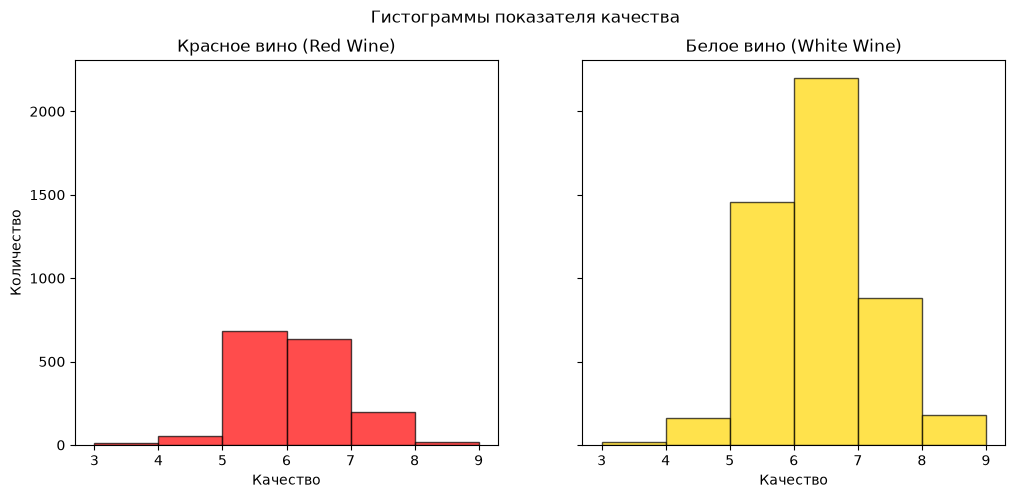


--- Вывод по вопросу 1 ---
В датасете присутствуют только числовые признаки (непрерывные).
Цвет (color) - категориальный (строковый) признак. Качество (quality) - дискретное целое число.
Для алгоритма K-Means мы будем использовать все столбцы, КРОМЕ 'quality' и 'color'.


In [2]:
print("--- Анализ характеристик ---")
# 1. Определяем непрерывные, категориальные и булевы признаки
print("Информация о датафрейме (типы данных):")
print(df.dtypes)

# 2. Сколько записей имеется для двух цветов вина и диапазона показателей качества?
print("\nКоличество записей по цветам вина:")
print(df['color'].value_counts())

print("\nДиапазон показателей качества (quality):")
print(f"Мин: {df['quality'].min()}, Макс: {df['quality'].max()}")
print(df['quality'].value_counts().sort_index())

# 3. Гистограммы показателя качества для каждого цвета
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Для красного вина
red_wine = df[df['color'] == 'red']
axes[0].hist(red_wine['quality'], bins=range(3, 10), edgecolor='black', color='red', alpha=0.7)
axes[0].set_title('Красное вино (Red Wine)')
axes[0].set_xlabel('Качество')
axes[0].set_ylabel('Количество')

# Для белого вина
white_wine = df[df['color'] == 'white']
axes[1].hist(white_wine['quality'], bins=range(3, 10), edgecolor='black', color='gold', alpha=0.7)
axes[1].set_title('Белое вино (White Wine)')
axes[1].set_xlabel('Качество')

plt.suptitle('Гистограммы показателя качества')
plt.show()

print("\n--- Вывод по вопросу 1 ---")
print("В датасете присутствуют только числовые признаки (непрерывные).")
print("Цвет (color) - категориальный (строковый) признак. Качество (quality) - дискретное целое число.")
print("Для алгоритма K-Means мы будем использовать все столбцы, КРОМЕ 'quality' и 'color'.")

Типы данных для каждой записи. Реализация алгоритма K-means в библиотеке Scikit-learn рассчитана исключительно на работу с непрерывными данными (хотя иногда её применяют и для категориальных или булевых типов). К счастью, все столбцы, которые мы будем использовать (все, кроме «quality» и «color»), являются непрерывными.

## Вопрос 2

* Оцените корреляцию и асимметрию соответствующих переменных — всех, кроме цвета и качества.
* Проведите необходимые преобразования признаков и/или масштабирование.
* Проанализируйте парное распределение переменных с помощью парных графиков, чтобы проверить правильность масштабирования и нормализации.


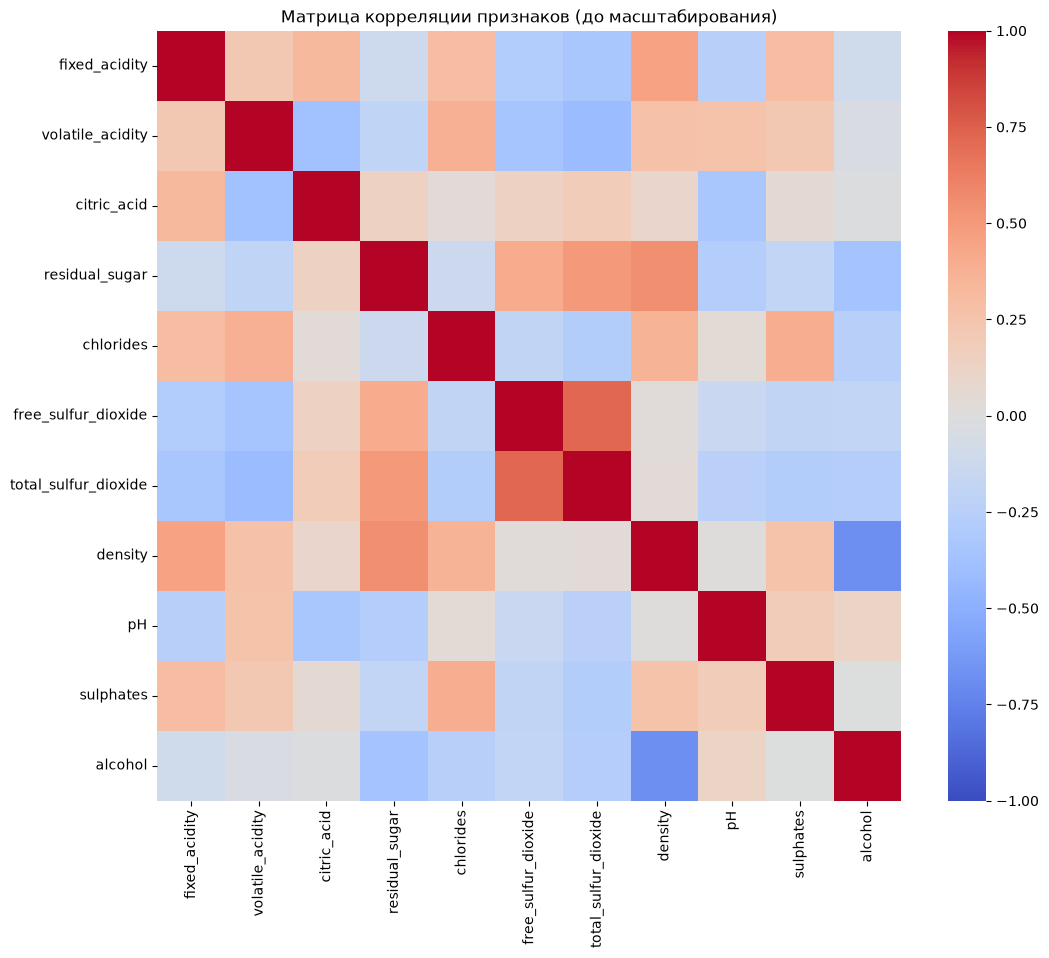

--- Асимметрия (Skewness) признаков ---
chlorides               5.399828
sulphates               1.797270
fixed_acidity           1.723290
volatile_acidity        1.495097
residual_sugar          1.435404
free_sulfur_dioxide     1.220066
alcohol                 0.565718
density                 0.503602
citric_acid             0.471731
pH                      0.386839
total_sulfur_dioxide   -0.001177
dtype: float64

Вывод: Признаки 'residual_sugar' и 'chlorides' имеют сильную правую асимметрию (skew > 1).

--- Асимметрия (Skewness) после масштабирования ---
chlorides               5.399828
sulphates               1.797270
fixed_acidity           1.723290
volatile_acidity        1.495097
residual_sugar          1.435404
free_sulfur_dioxide     1.220066
alcohol                 0.565718
density                 0.503602
citric_acid             0.471731
pH                      0.386839
total_sulfur_dioxide   -0.001177
dtype: float64


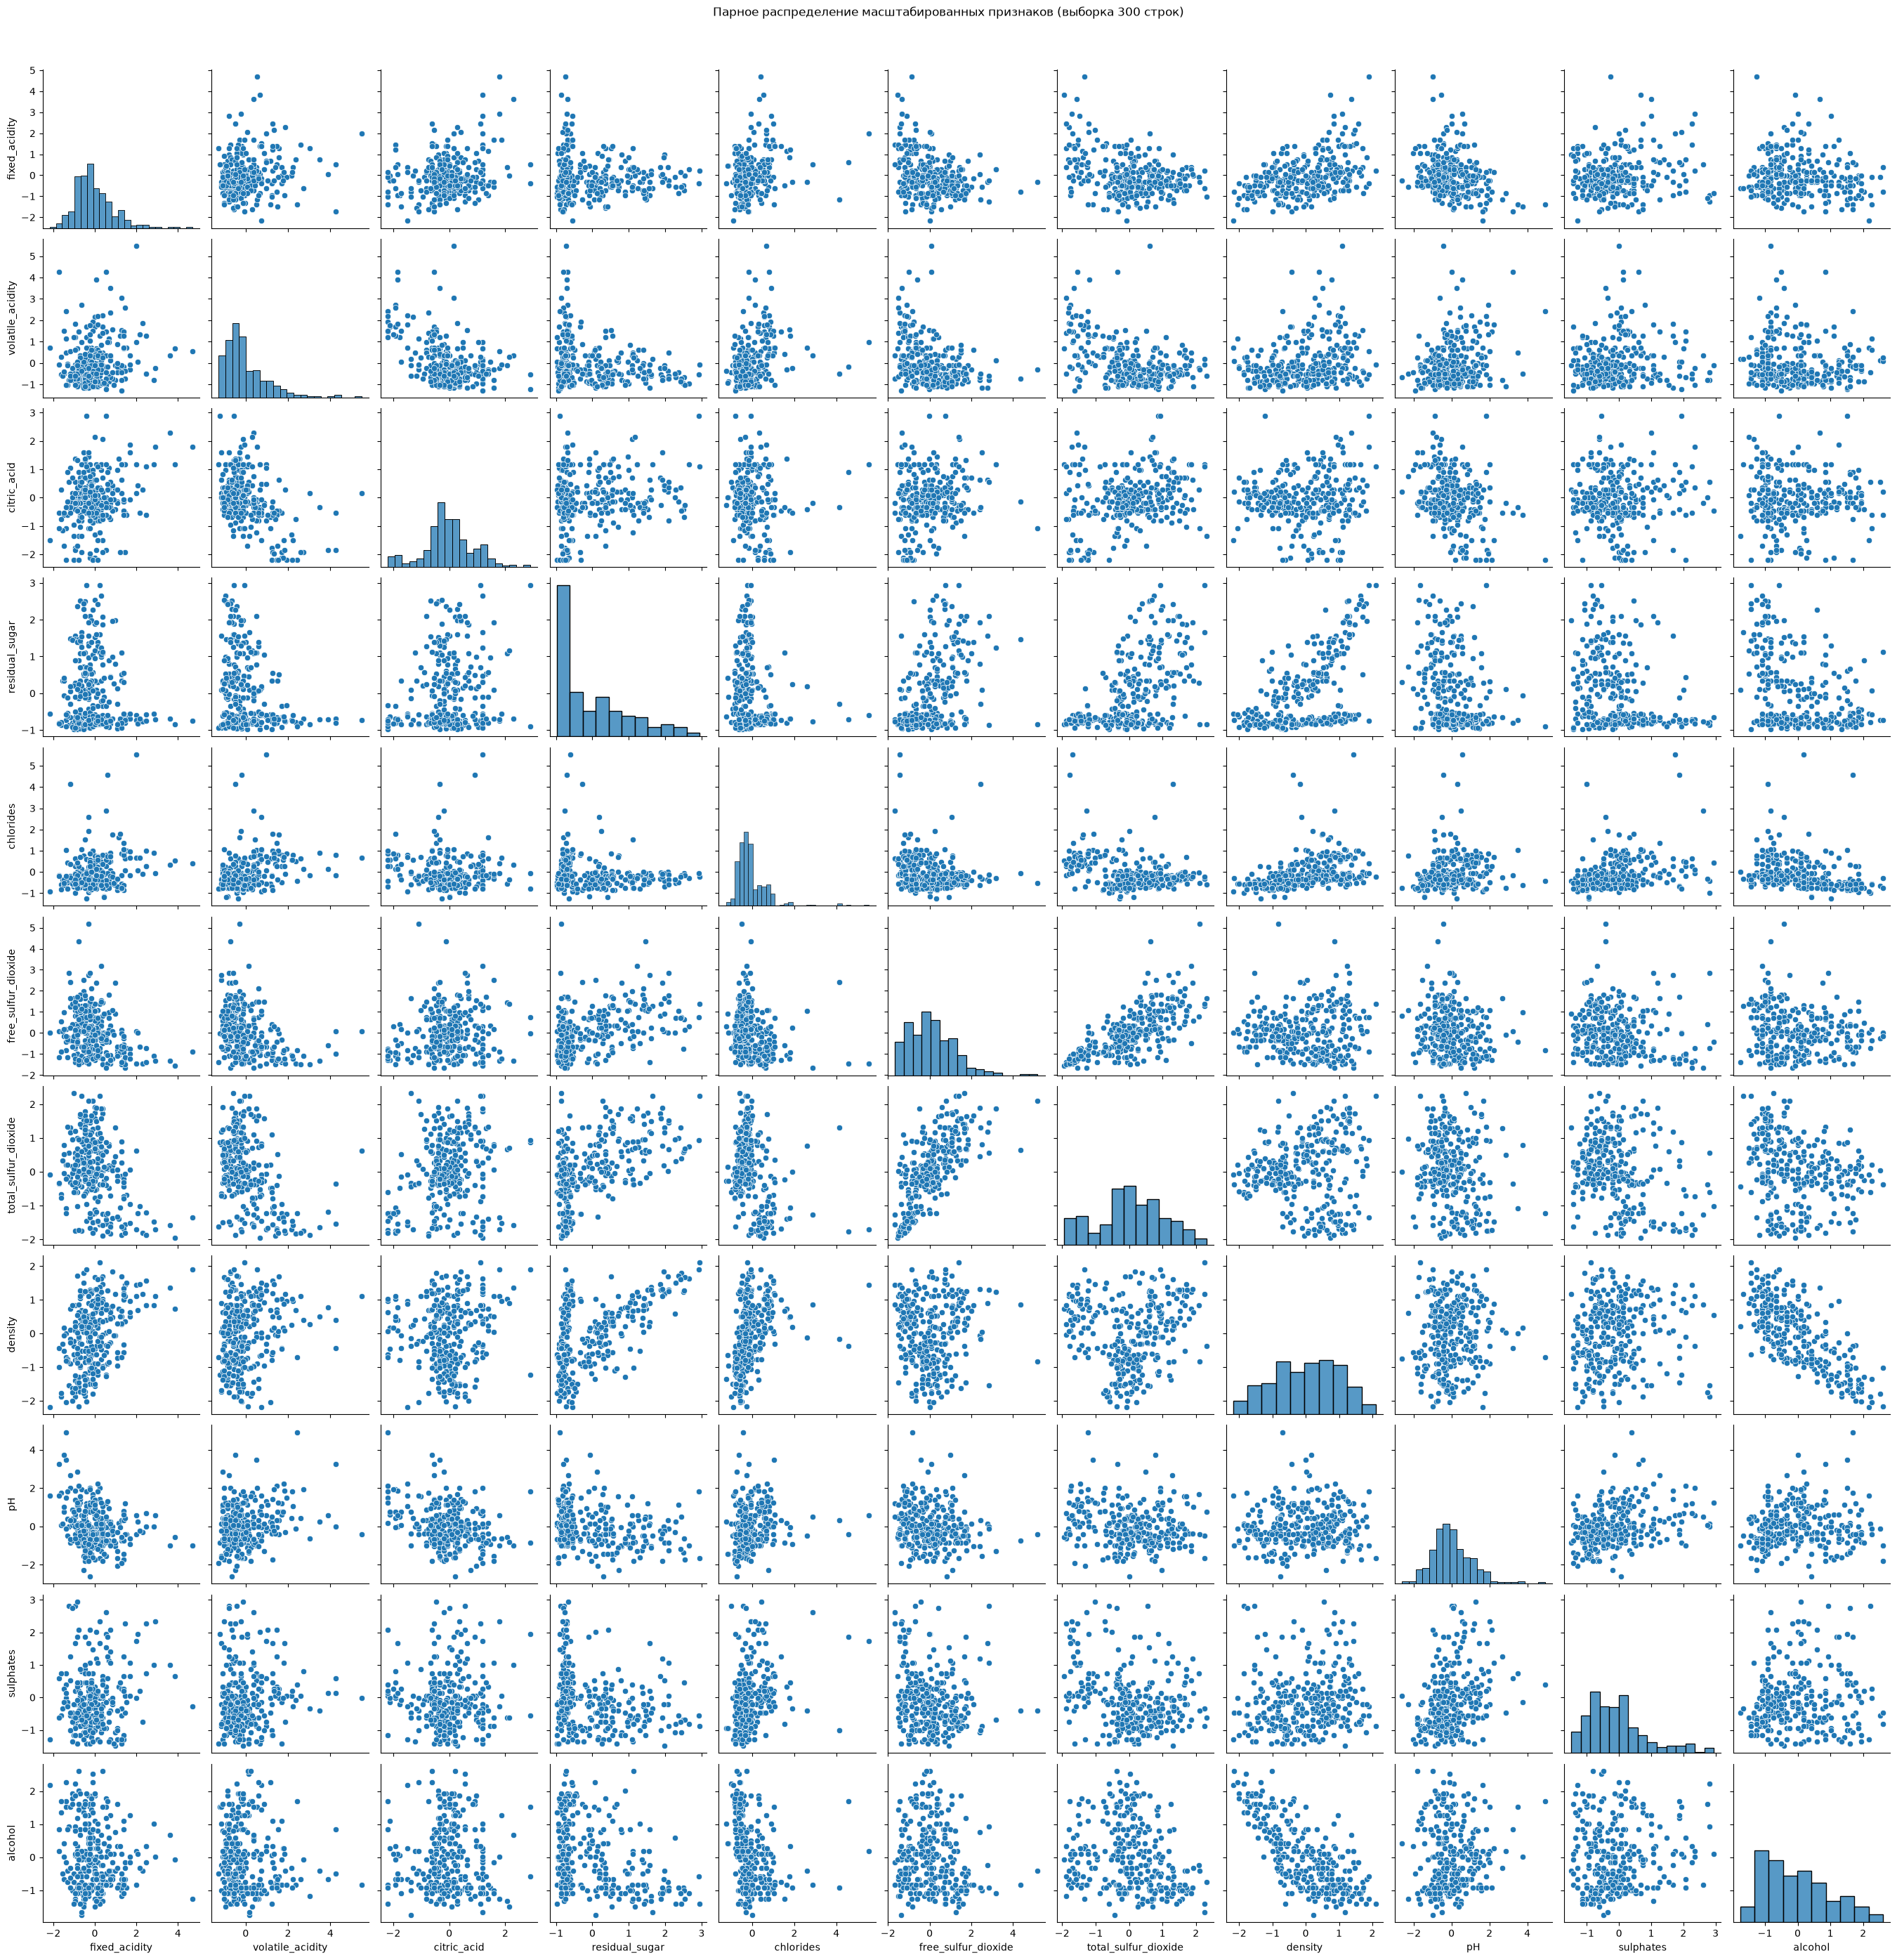

In [3]:
# 1. Отделяем признаки для кластеризации (все, кроме color и quality)
X = df.drop(columns=['color', 'quality'])

# 2. Оценка корреляции
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матрица корреляции признаков (до масштабирования)')
plt.show()

# 3. Анализ асимметрии (skewness) в преддверии преобразований
print("--- Асимметрия (Skewness) признаков ---")
skewness = X.skew().sort_values(ascending=False)
print(skewness)
print("\nВывод: Признаки 'residual_sugar' и 'chlorides' имеют сильную правую асимметрию (skew > 1).")

# 4. Масштабирование (StandardScaler)
# K-Means чувствителен к масштабу, поэтому это критически важно
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)

# Возвращаем в DataFrame для удобства визуализации
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)

print("\n--- Асимметрия (Skewness) после масштабирования ---")
print(X_scaled.skew().sort_values(ascending=False))

# 5. Парные графики (Pairplot)
# Поскольку признаков много (11), график будет огромным. 
# Для наглядности возьмем подвыборку из 300 строк.
sample_idx = np.random.choice(len(X_scaled), 300, replace=False)
X_sample = X_scaled.iloc[sample_idx]

sns.pairplot(X_sample)
plt.suptitle('Парное распределение масштабированных признаков (выборка 300 строк)', y=1.02)
plt.show()

А также анализ значений асимметрии в преддверии преобразований.

## Вопрос 3

* Постройте модель кластеризации методом K-средних с двумя кластерами.
* Проанализируйте кластеры по цвету вина.

--- Анализ кластеров по цвету вина ---
Реальный цвет (0=Белое, 1=Красное)     0     1
Кластер K-Means                               
0                                   4831    24
1                                     67  1575

--- Отчет классификации (K-Means vs Реальный цвет) ---
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      4898
           1       0.96      0.98      0.97      1599

    accuracy                           0.99      6497
   macro avg       0.98      0.99      0.98      6497
weighted avg       0.99      0.99      0.99      6497



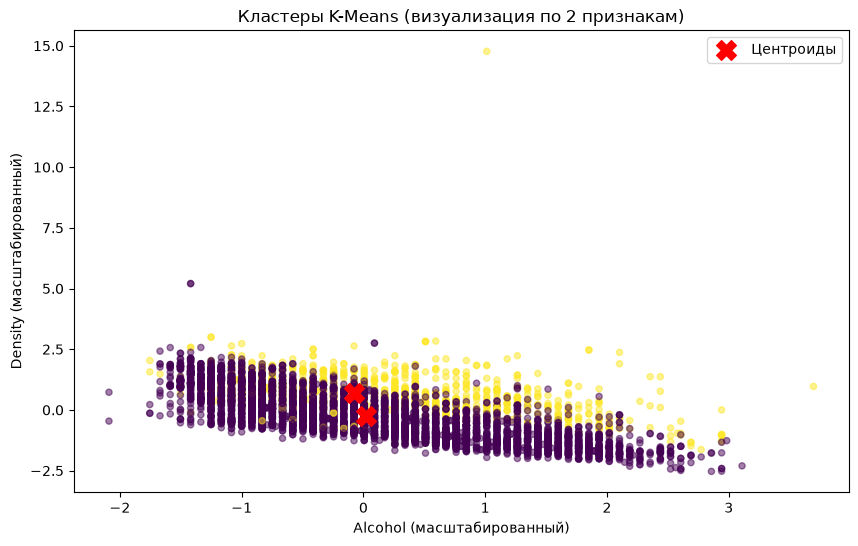

In [4]:
# 1. Создаем и обучаем модель K-Means с 2 кластерами
# random_state нужен для воспроизводимости результатов
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Получаем метки кластеров для каждой записи
cluster_labels = kmeans.labels_

# 2. Сравниваем кластеры с реальным цветом вина
# Перекодируем цвет в 0 и 1, чтобы сравнить с метками кластеров
true_colors = (df['color'] == 'red').astype(int)

print("--- Анализ кластеров по цвету вина ---")
# Смотрим, сколько красных и белых вин попало в каждый кластер
comparison_df = pd.DataFrame({
    'Cluster': cluster_labels,
    'True_Color': true_colors
})

print(pd.crosstab(comparison_df['Cluster'], comparison_df['True_Color'], rownames=['Кластер K-Means'], colnames=['Реальный цвет (0=Белое, 1=Красное)']))

# 3. Вывод отчета классификации
# (Рассматриваем кластеры как предсказания модели)
print("\n--- Отчет классификации (K-Means vs Реальный цвет) ---")
# Внимание: K-Means не знает, какой кластер "0", а какой "1", он просто группирует данные.
# Возможно, придется инвертировать метки (1 - cluster_labels) для правильного отчета, если точность низкая.
print(classification_report(true_colors, cluster_labels))

# 4. Визуализация кластеров (например, по двум самым важным признакам)
# В качестве примера возьмем 'alcohol' и 'density'
plt.figure(figsize=(10, 6))
plt.scatter(X_scaled['alcohol'], X_scaled['density'], c=cluster_labels, cmap='viridis', alpha=0.5, s=20)
plt.scatter(kmeans.cluster_centers_[:, X.columns.get_loc('alcohol')], 
            kmeans.cluster_centers_[:, X.columns.get_loc('density')], 
            c='red', marker='X', s=200, label='Центроиды')
plt.xlabel('Alcohol (масштабированный)')
plt.ylabel('Density (масштабированный)')
plt.title('Кластеры K-Means (визуализация по 2 признакам)')
plt.legend()
plt.show()

## Вопрос 4

* Теперь постройте модели K-Means с количеством кластеров от 1 до 20.
* Для каждой модели запишите количество кластеров и значение инерции.
* Постройте график зависимости количества кластеров от инерции. Можно ли выделить какое-то идеальное количество кластеров?

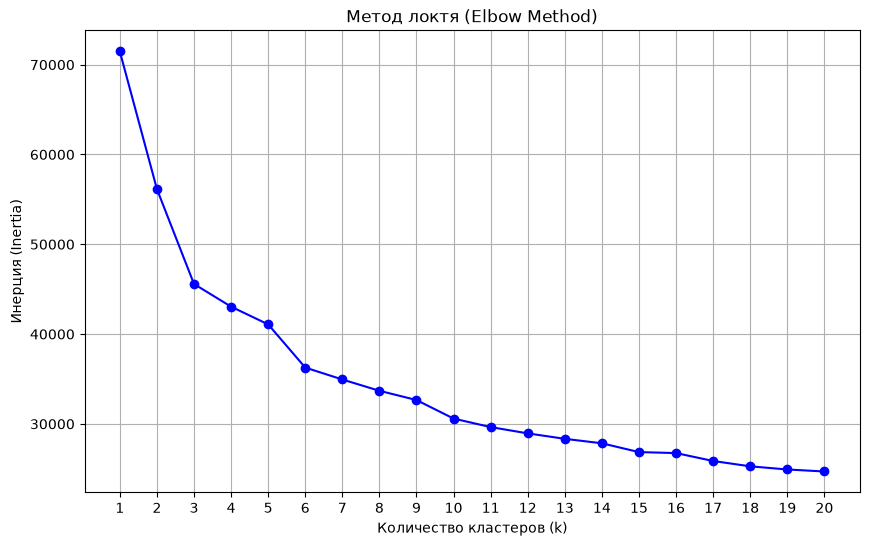

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Предполагается, что X_scaled уже создан в Вопросе 2
inertias = []
k_range = range(1, 21)

for k in k_range:
    # n_init='auto' подавляет предупреждения в новых версиях sklearn
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertias, marker='o', linestyle='-', color='b')
plt.title('Метод локтя (Elbow Method)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Инерция (Inertia)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

## Вопрос 5

* Постройте модель агломеративного кластеризации с двумя кластерами.
* Сравните полученные результаты с результатами, полученными с помощью алгоритма K-средних, с точки зрения цвета вина.
* Визуализируйте дендрограмму, построенную с помощью агломеративного кластеризации. *Подсказка:* В SciPy есть модуль [`cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html#module-scipy.cluster.hierarchy), содержащий функции `linkage` и `dendrogram`, необходимые для построения карты связей и отображения полученной дендрограммы.

Сравнение кластеров (Агломеративный vs K-Means):
K-Means           0     1
Agglomerative            
0                23  4733
1              1620   121


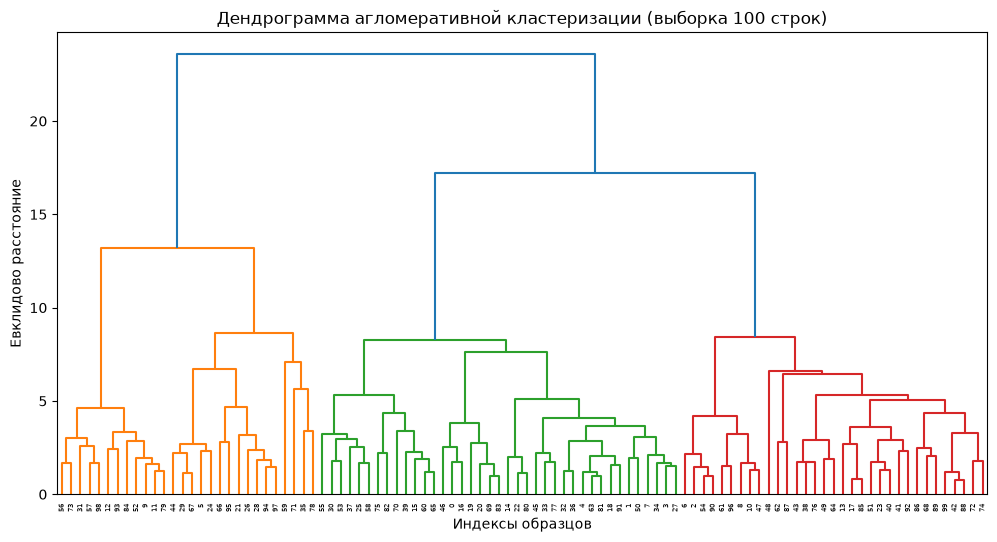

In [6]:
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch
import numpy as np
import pandas as pd

# 1. Модель агломеративной кластеризации
agg_clustering = AgglomerativeClustering(n_clusters=2)
agg_labels = agg_clustering.fit_predict(X_scaled)

# 2. Сравнение с результатами K-Means и реальным цветом
# Перекодируем реальный цвет
true_colors = (df['color'] == 'red').astype(int)

# Для K-Means возьмем модель из Вопроса 3
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init='auto')
kmeans_labels = kmeans_2.fit_predict(X_scaled)

comparison = pd.crosstab(agg_labels, kmeans_labels, rownames=['Agglomerative'], colnames=['K-Means'])
print("Сравнение кластеров (Агломеративный vs K-Means):")
print(comparison)

# 3. Визуализация дендрограммы
# Используем подвыборку данных, так как полная дендрограмма будет нечитаемой (будет "каша")
sample_indices = np.random.choice(X_scaled.shape[0], 100, replace=False)
X_sample = X_scaled.iloc[sample_indices]

plt.figure(figsize=(12, 6))
plt.title('Дендрограмма агломеративной кластеризации (выборка 100 строк)')
# Метод 'ward' минимизирует дисперсию внутри кластеров (аналог K-Means)
dendrogram = sch.dendrogram(sch.linkage(X_sample, method='ward'))
plt.xlabel('Индексы образцов')
plt.ylabel('Евклидово расстояние')
plt.show()

Обратите внимание, что распределение по кластерам является произвольным: номера основных кластеров для красного и белого цветов могут не совпадать с приведёнными ниже, а также могут различаться при использовании метода K-средних и агломеративного кластерирования.

## Вопрос 6

В этом вопросе мы рассмотрим кластеризацию как один из способов инженерии признаков.

* Создайте **бинарную** целевую переменную `y`, указывающую, превышает ли показатель качества значение 7 или нет.
* Создайте переменную `X_with_kmeans` на основе набора данных `data`, удалив из него столбцы «quality», «color» и «agglom». Создайте из него `X_without_kmeans`, удалив столбец «kmeans».
* Для обоих наборов данных с помощью `StratifiedShuffleSplit` с 10 разбиениями обучите 10 классификаторов Random Forest и вычислите среднее значение показателей ROC-AUC.
* Сравните средние значения показателей ROC-AUC для моделей, использующих кластеры k-средних в качестве признака, и для модели, которая их не использует.

Средний ROC-AUC С K-Means: 0.8942
Средний ROC-AUC БЕЗ K-Means: 0.9032

--- Влияние количества кластеров на Logistic Regression ---
Базовый ROC-AUC (без кластеров): 0.7893


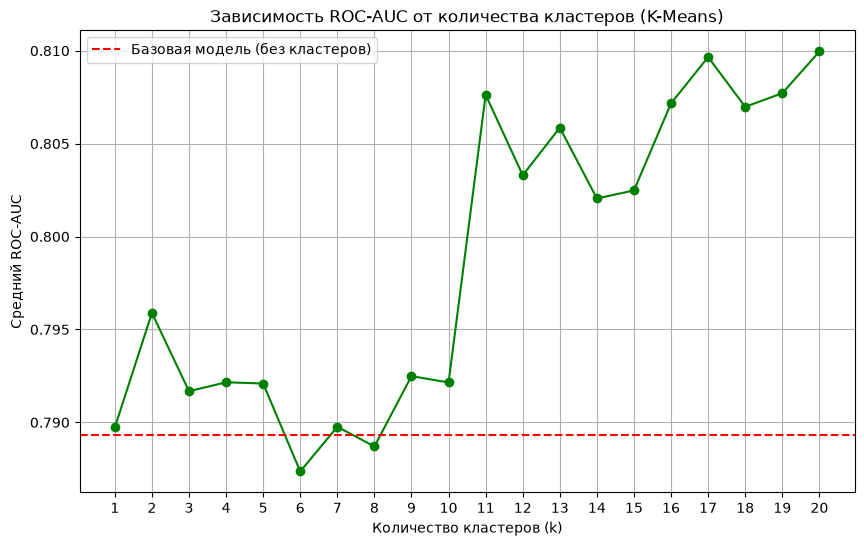

In [7]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# 1. Создаем бинарную целевую переменную y (1, если quality > 7, иначе 0)
y = (df['quality'] > 7).astype(int)

# 2. Переменная X_with_kmeans на основе data (удаляем color и quality)
data_with_kmeans = df.drop(columns=['color', 'quality']).copy()
data_with_kmeans['kmeans'] = kmeans_labels # Используем метки из Вопроса 5

# Переменная X_without_kmeans (удаляем kmeans)
X_without_kmeans = data_with_kmeans.drop(columns=['kmeans'])

# 3. Обучение 10 моделей Random Forest и вычисление ROC-AUC
# Для чистоты эксперимента будем использовать StratifiedShuffleSplit с 10 разбиениями
sss = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)

auc_with_kmeans = []
auc_without_kmeans = []

for train_index, test_index in sss.split(X_without_kmeans, y):
    # Разделение данных
    X_train_with = data_with_kmeans.iloc[train_index]
    X_test_with = data_with_kmeans.iloc[test_index]
    
    X_train_without = X_without_kmeans.iloc[train_index]
    X_test_without = X_without_kmeans.iloc[test_index]
    
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
    # Модель с K-Means
    rf_with = RandomForestClassifier(random_state=42)
    rf_with.fit(X_train_with, y_train)
    y_pred_proba_with = rf_with.predict_proba(X_test_with)[:, 1]
    auc_with_kmeans.append(roc_auc_score(y_test, y_pred_proba_with))
    
    # Модель без K-Means
    rf_without = RandomForestClassifier(random_state=42)
    rf_without.fit(X_train_without, y_train)
    y_pred_proba_without = rf_without.predict_proba(X_test_without)[:, 1]
    auc_without_kmeans.append(roc_auc_score(y_test, y_pred_proba_without))

print(f"Средний ROC-AUC С K-Means: {np.mean(auc_with_kmeans):.4f}")
print(f"Средний ROC-AUC БЕЗ K-Means: {np.mean(auc_without_kmeans):.4f}")

# =====================================================================
# Дополнительная часть: Влияет ли количество кластеров?
# =====================================================================
print("\n--- Влияние количества кластеров на Logistic Regression ---")

# Базовый набор (только числа с плавающей запятой)
base_data = df.select_dtypes(include=['float64']).copy()
X_base = base_data

# 1. Базовый ROC-AUC (без кластеров)
auc_base = []
for train_index, test_index in sss.split(X_base, y):
    X_tr, X_te = X_base.iloc[train_index], X_base.iloc[test_index]
    y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
    
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_tr, y_tr)
    auc_base.append(roc_auc_score(y_te, lr.predict_proba(X_te)[:, 1]))
print(f"Базовый ROC-AUC (без кластеров): {np.mean(auc_base):.4f}")

# 2. Цикл по k = 1..20
k_values = range(1, 21)
mean_auc_k = []

# Для one-hot кодирования кластеров
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

for k in k_values:
    # Обучаем K-Means на ВСЕХ данных (для простоты)
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    clusters = km.fit_predict(X_scaled)
    
    # Создаем новый датафрейм с базовыми признаками
    X_temp = X_base.copy()
    
    # One-hot кодирование кластеров
    # Важно: для корректной работы в цикле кросс-валидации лучше делать fit_transform внутри цикла, 
    # но для базовой оценки можно сделать так:
    cluster_encoded = encoder.fit_transform(clusters.reshape(-1, 1))
    cluster_df = pd.DataFrame(cluster_encoded, columns=[f'cluster_{i}' for i in range(k)])
    
    X_temp = pd.concat([X_temp, cluster_df], axis=1)
    
    # Оценка с кросс-валидацией
    auc_k = []
    for train_index, test_index in sss.split(X_temp, y):
        X_tr, X_te = X_temp.iloc[train_index], X_temp.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        
        lr = LogisticRegression(max_iter=1000)
        lr.fit(X_tr, y_tr)
        auc_k.append(roc_auc_score(y_te, lr.predict_proba(X_te)[:, 1]))
    
    mean_auc_k.append(np.mean(auc_k))

# 3. График зависимости ROC-AUC от количества кластеров
plt.figure(figsize=(10, 6))
plt.plot(k_values, mean_auc_k, marker='o', linestyle='-', color='g')
plt.axhline(y=np.mean(auc_base), color='r', linestyle='--', label='Базовая модель (без кластеров)')
plt.title('Зависимость ROC-AUC от количества кластеров (K-Means)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Средний ROC-AUC')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

Давайте теперь выясним, влияет ли количество кластеров на это улучшение.

* Создайте базовый обучающий набор из `data`, ограничив его столбцами с числами с плавающей запятой.
* Для $n = 1, \ldots, 20$ выполните обучение алгоритма k-средних с $n$ кластерами. Примените к данным кодирование «one-hot» и добавьте их в **базовый** обучающий набор. Не добавляйте их к результатам предыдущей итерации.
* Обучите 10 моделей **логистической регрессии** и вычислите среднее значение показателя ROC-AUC.
* Постройте график средних значений показателя ROC-AUC.